# 4 · comedy2d：二维中的水流、两个动力学相和多余水源项

**这一篇学什么**

- 二维饱和流场（`Darcy`）驱动对流–弥散（`Transport(q=flow.q)`）
- 两个动力学相，表面积模型 3，子步和下限检查（OGS 2017 规则）
- **多余水源项**：GEMS 的体积变化反馈到水流
- OGS 源码里一个隐藏开关（未初始化的变量）怎样决定结果

## 问题

14 × 14 cm 的饱和方形区域（OGS5GEMDEV `PETSc/comedy2d`）。一条竖直的水泥带（x = 8 – 10 cm）把两块砂区隔开。
NaCl 溶液从左上方进入，草酸钠溶液从顶部进入，水从右侧流出（定水头）。草酸根在水泥带和 portlandite 反应生成草酸钙（CaOxaHyd）。

这个基准从 OGS 大约 7.5 天时的状态重启，只算 **6 步（68 s）**。这段时间溶质移动不到 1 mm；有意义的变化都在水泥带里的反应前锋上。

| 量 | 值 | OGS 文件 |
|---|---|---|
| 网格 | 42 × 42 四边形，3 种材料 | `cement2d.msh` |
| 渗透系数 | 10⁻⁵ m/s（砂），1.64·10⁻⁶ m/s（水泥） | `cement2d.mmp` |
| 注入 | 5.7143·10⁻¹⁰ 和 1.1429·10⁻⁹ m³/s，**每个入口节点** | `cement2d.st` |
| 弥散度、扩散 | 0.02 m；3.33·10⁻⁹ m²/s × 曲折度 | `cement2d.mmp`、`.mcp` |
| 动力学 | Portlandite、CaOxaHyd：$\log k=-5$，表面积模型 3，1000 m²/m³ | `cement2d.gem` |
| 时间步 | 10 s × 1.05ᵏ，k = 0…5 | `cement2d.tim` |
| 起点 | OGS 约 7.5 天时的重启文件 | `cement2d_*_gem.asc` |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

ROOT = next(p / 'GEMS_FEniCSx_OGS5_Template' for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'GEMS_FEniCSx_OGS5_Template').exists())
sys.path.insert(0, str(ROOT))
from ogs_io import read_msh, read_restart, read_gli, nodes_on_polyline
from fe_mesh import OGSMesh
from flow import Darcy
from transport import Transport
from gems_ogs import OGSGEMS, Kinetic
from reactive_transport import run
from compare import error_table

CASE = ROOT / 'cases' / '4_comedy2d'
OGS = CASE / 'ogs_input'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})

## 网格、水流和输运

`Darcy` 组装 $-\nabla\cdot(K\nabla h) = Q$，并把通量 `flow.q` 作为 UFL 表达式给出。把它传给 `Transport`，对流项就在每个积分点上用
$-K\nabla h$，和 OGS 一样。注意 OGS 的一个细节：折线上的 `CONSTANT` 源项给折线上**每个节点同样的值**（不按长度分配）。

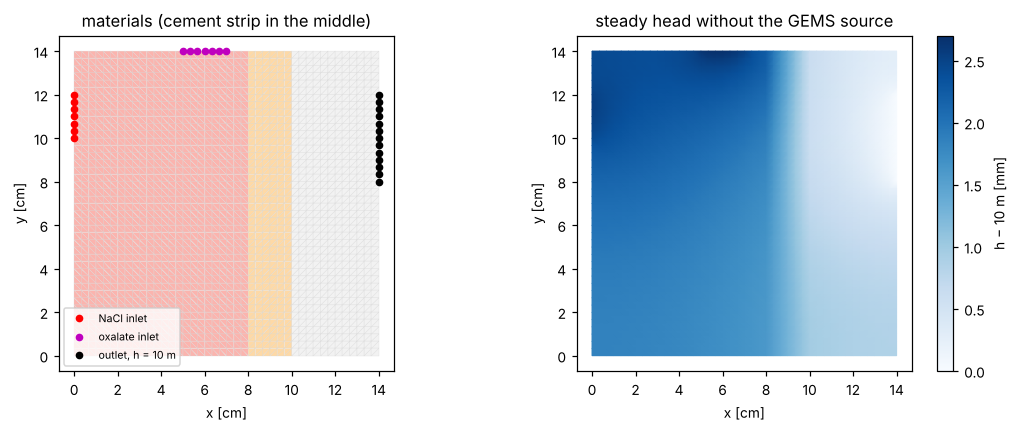

In [2]:
points, cells, mats, _ = read_msh(OGS / 'cement2d.msh')
mesh = OGSMesh(points[:, :2], cells['quad'], 'quadrilateral')
mat = mats['quad']
_, lines = read_gli(OGS / 'cement2d.gli')
inlet1 = nodes_on_polyline(mesh.points, lines['INLET_1'][:, :2], 1e-4)
inlet2 = nodes_on_polyline(mesh.points, lines['INLET_2'][:, :2], 1e-4)
outlet = nodes_on_polyline(mesh.points, lines['OUTLET'][:, :2], 1e-4)
inlets = np.r_[inlet1, inlet2]

K_mat = np.array([1.0e-5, 1.64e-6, 1.0e-5])
tau_mat = np.array([1.0, 1.578949, 1.0])
flow = Darcy(mesh, fixed_nodes=outlet)
flow.K_cell, flow.fixed_values = K_mat[mat], 10.0
flow.sources[inlet1], flow.sources[inlet2] = 5.7143e-10, 11.429e-10

bc_inlet1 = np.array([9.96740295734440e-04, 1.99348059146888e-03, 1.99362013511029e+01, 1.01064827675428e-03,
                      1.99348059146889e+01, 2.27326337437258e-02, 9.96740295734440e-04, 0.0])
bc_inlet2 = np.array([9.86453094520442e-06, 9.86453094519933e-06, 1.68789503224731e-05, 1.58035254545903e-01,
                      7.89162492495330e+02, 1.98600359071739e-02, 3.94660154055751e+02, 0.0])
tr = Transport(mesh, fixed_nodes=inlets, q=flow.q, alpha_L=0.02, alpha_T=0.02)
tr.fixed_values = np.vstack([np.tile(bc_inlet1, (len(inlet1), 1)), np.tile(bc_inlet2, (len(inlet2), 1))])

p = mesh.points * 100
tri = mtri.Triangulation(p[:, 0], p[:, 1], np.vstack([mesh.cells[:, [0, 1, 2]], mesh.cells[:, [0, 2, 3]]]))
h = flow.solve()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].tripcolor(tri, facecolors=np.r_[mat, mat], cmap='Pastel1', edgecolors='0.85', lw=0.2)
for nodes, col, lab in [(inlet1, 'r', 'NaCl inlet'), (inlet2, 'm', 'oxalate inlet'), (outlet, 'k', 'outlet, h = 10 m')]:
    ax[0].plot(p[nodes, 0], p[nodes, 1], 'o', color=col, ms=4, label=lab)
ax[0].set_title('materials (cement strip in the middle)'); ax[0].legend(fontsize=7, loc='lower left')
m = ax[1].tripcolor(tri, (h - 10) * 1e3, shading='gouraud', cmap='Blues'); fig.colorbar(m, ax=ax[1], label='h − 10 m [mm]')
ax[1].set_title('steady head without the GEMS source')
for a in ax: a.set_aspect('equal'); a.set_xlabel('x [cm]'); a.set_ylabel('y [cm]')
plt.tight_layout(); plt.show()

## 化学：OGS 2017 的规则

参考解是 2017 年 3 月的 OGS-GEM 代码算的，所以化学部分用那一版的规则：只有 $\Omega \ge 1.1$ **且**速率不为零时才成核、
下限检查（`CheckConstraints`）、动力学子步（`MaxDtKinetics`）。`retry_perturb=1e-12` *不是* OGS 的规则：
现在的 GEMS3K 偶尔会因为舍入误差在一个前锋节点上失败，把输入第 12 位有效数字改一下再算就收敛了。

隐藏开关：那一版代码里变量 `flag_loose_kinetics` 从没被初始化，输入文件也没设它。我们两种可能都算：`limits='loose'` 和 `'strict'`。

In [3]:
def simulate(limits):
    chem = OGSGEMS(CASE / 'gems' / 'I1SetUp-dat.lst', mesh.n_nodes, hydrology='full', min_porosity=1e-6,
                   kinetics=[Kinetic('Portlandite', logk=(-5.0,), area_model=3, area=1000.0),
                             Kinetic('CaOxaHyd', logk=(-5.0,), area_model=3, area=1000.0)],
                   limits=limits, seed_omega=1.1, seed_needs_rate=True, check_lower_limits=True,
                   substep_kinetics=True, retry_perturb=1e-12, boundary_nodes=inlets)
    restart = read_restart(OGS / 'cement2d', mesh.n_nodes, chem.nIC, chem.nDC)
    chem.init_from_restart(restart, restart['solute'], update_porosity=False, pin_kinetic=True)

    def prepare(step, t, dt):
        tr.phi_cell = chem.phi[mesh.cells].mean(1)
        tr.De_cell = tr.phi_cell * 3.333333e-9 * tau_mat[mat]

    log = run(chem, tr, [10.0 * 1.05 ** k for k in range(6)], flow=flow, mobile=list(range(8)), prepare=prepare, print_every=0)
    print(f"{limits:6s}: t = {log.t.iloc[-1]:.4f} s, {log.wall_s.iloc[-1]:.0f} s; failed nodes per step {log.failed.tolist()}, "
          f"sub-stepped nodes {log.substepped.tolist()}")
    return chem, restart, flow.head.copy()

runs = {lim: simulate(lim) for lim in ('loose', 'strict')}

loose : t = 68.0191 s, 9 s; failed nodes per step [0, 0, 0, 0, 0, 0], sub-stepped nodes [1, 0, 1, 0, 0, 0]


strict: t = 68.0191 s, 9 s; failed nodes per step [0, 0, 0, 0, 0, 0], sub-stepped nodes [1, 0, 1, 1, 4, 6]


## 和 OGS 比较（t = 68 s）

离前锋远的地方 68 s 里几乎没变化，所以整体误差小说明不了什么。第二张图比较的是**计算期间的变化量**（68 s 的结果减去重启状态）——这才是真正的检验。

,"max rel. diff, loose","max rel. diff, strict"
quantity,,
1-C,1.2e-05,3.8e-04
2-Ca,1.4e-04,5.6e-01
3-Cl,4.6e-06,5.1e-05
4-H,2.8e-05,1.7e-02
5-Na,2.9e-05,5.9e-04
6-O,2.8e-05,1.7e-02
7-Oxa,9.0e-06,4.4e-02
NodePorosity,5.9e-08,1.2e-04
pH,1.2e-04,6.5e-04


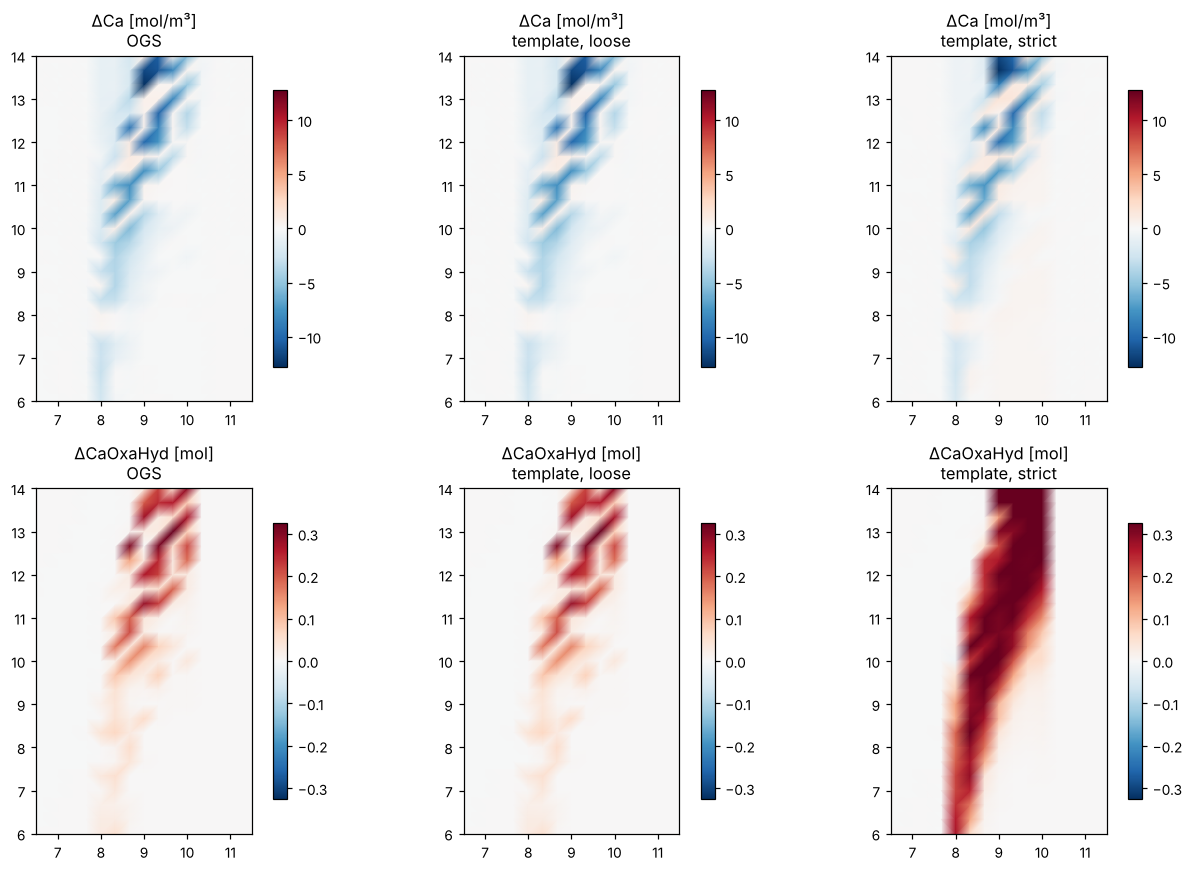

In [4]:
ref = np.load(CASE / 'reference' / 'ref_t68s.npz')
names = ['1-C', '2-Ca', '3-Cl', '4-H', '5-Na', '6-O', '7-Oxa']
tables = []
for lim, (chem, restart, head) in runs.items():
    ours = {**{n: chem.c[:, k] for k, n in enumerate(names)}, 'NodePorosity': chem.phi, 'pH': chem.pH, 'HEAD': head,
            'Portlandite': chem.amounts('Portlandite'), 'CaOxaHyd': chem.amounts('CaOxaHyd')}
    t = error_table(ours, {k: ref['node__' + k] for k in ours})
    tables.append(t.set_index('quantity')['max_rel_diff'].rename(f'max rel. diff, {lim}'))
display(pd.concat(tables, axis=1).style.format('{:.1e}'))

chem, restart = runs['loose'][0], runs['loose'][1]
j = chem.species.index('CaOxaHyd')
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for row, (label, d_ref, d_fun) in enumerate([
        ('ΔCa [mol/m³]', ref['node__2-Ca'] - restart['solute'][:, 1], lambda c: c.c[:, 1] - restart['solute'][:, 1]),
        ('ΔCaOxaHyd [mol]', ref['node__CaOxaHyd'] - restart['xDC'][:, j], lambda c: c.amounts('CaOxaHyd') - restart['xDC'][:, j])]):
    lim = np.abs(d_ref).max()
    for col, (title, val) in enumerate([('OGS', d_ref), ('template, loose', d_fun(runs['loose'][0])),
                                         ('template, strict', d_fun(runs['strict'][0]))]):
        ax = axes[row, col]
        m = ax.tripcolor(tri, val, shading='gouraud', cmap='RdBu_r', vmin=-lim, vmax=lim)
        fig.colorbar(m, ax=ax, shrink=0.8)
        ax.set_xlim(6.5, 11.5); ax.set_ylim(6, 14); ax.set_aspect('equal'); ax.set_title(f'{label}\n{title}')
plt.tight_layout(); plt.show()

用 `loose` 时变化的空间分布和 OGS 逐节点吻合（Ca 差 $1.4\times10^{-4}$ 以内，水头差 $10^{-9}$ 以内）；用 `strict` 时 portlandite 在强烈欠饱和的节点上一直溶解，
Ca 差 50 % 以上。所以生成参考解时那个未初始化的变量实际上是*非零*的。

## 复现时遇到的坑

1. **哪个版本的代码？** 参考 `.vtk` 是 2017 年 3 月重新生成的；那之后 `rf_REACT_GEM.cpp` 又改了二十多次。所有规则都要照那一版
   （`git show 8e2cf24:...`），不能照最新代码。
2. **一个未初始化的变量**（`flag_loose_kinetics`）决定动力学上下限是宽松还是严格。新版 OGS 把它初始化成 0，会得到 `strict` 的结果。
3. **窄窗口里 GEMS 停在上限**，即使这个相强烈欠饱和。宽松上下限（上限 = 当前量）下，portlandite 实际上溶解不了。
   这个基准的结果有一部分是 GEMS 的数值行为，不是物理过程。
4. **重启初始化**对*所有*节点（包括入口）算 GEMS，然后把动力学相钉住（`pin_kinetic=True`），孔隙率保留文件值（`update_porosity=False`）。
   浓度取 `m_bIC_gem.asc` 的第二列。
5. **折线源项**按节点给，不按长度。
6. **OGS 输出的单元速度**取第 0 个高斯点，不是单元中心（出口附近差 35 %）。
7. **`MaxDtKinetics` 返回的是最后一次算出的值，不是最小值**——照原样实现。

## 练习

1. 不加 GEMS 多余水源项再算（`run(..., water_source=False)`）。水头和速度变了多少？化学结果受影响吗？
2. 去掉 `retry_perturb`。哪个节点在哪一步失败？那时 Ca 的误差是什么样？
3. 把 `loose` 的计算接着算到 1 天（`dt` 按 1.05 增长到 1000 s）。CaOxaHyd 在哪里生成？